<a href="https://colab.research.google.com/github/madeeha-noor/Student-Success-Early-Warning/blob/main/notebooks/05_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 Clustering
Group students who look alike (K-means and hierarchical clustering) and describe each group as a student profile. The Target is not used to build the clusters, only to describe them afterwards.

In [ ]:
!pip install -q ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ds = fetch_ucirepo(id=697)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df.columns = df.columns.str.strip()
print(df.shape)

(4424, 37)


In [ ]:
numeric_cl = ['Application order', 'Age at enrollment', 'Admission grade',
              'Previous qualification (grade)',
              'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
              'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
              'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']

binary_cl = ['Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Gender',
            'Displaced', 'Daytime/evening attendance', 'Educational special needs', 'International']

cluster_cols = numeric_cl + binary_cl
X_cl = df[cluster_cols]
print('Columns used for clustering:', len(cluster_cols))
print('Missing values:', X_cl.isna().sum().sum())

Columns used for clustering: 18
Missing values: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cl)
print(X_scaled.shape)
print('Largest column mean:', np.abs(X_scaled.mean(axis=0)).max().round(3))
print('Column std values:', np.unique(X_scaled.std(axis=0).round(2)))

(4424, 18)
Largest column mean: 0.0
Column std values: [1.]


80% of the information needs 10 of 18 components
90% of the information needs 13 of 18 components
95% of the information needs 15 of 18 components


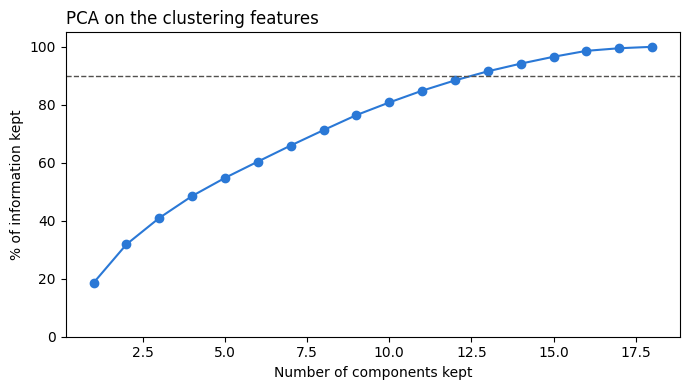

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(random_state=42).fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)
for goal in [0.80, 0.90, 0.95]:
  print(f"{goal:.0%} of the information needs {np.argmax(cum >= goal) + 1} of {len(cum)} components")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum) + 1), cum * 100, marker='o', color='#2a78d6')
ax.axhline(90, color='#52514e', linestyle='--', linewidth=1)
ax.set_xlabel('Number of components kept')
ax.set_ylabel('% of information kept')
ax.set_title('PCA on the clustering features', loc='left')
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

In [ ]:
n_comp = int(np.argmax(cum >= 0.90) + 1)
pca = PCA(n_components=n_comp, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print('Components kept:', n_comp, '| shape:', X_pca.shape)

Components kept: 13 | shape: (4424, 13)


## Features and preparation
- Clusters are built without the Target, which we only use afterwards to describe them
- We use 18 columns: 10 numeric (age, admission and previous grades, application order, 6 first-semester results) and 8 yes/no columns
- Left out: second-semester columns (they arrive late and partly result from leaving), the economic columns (national values per period, not student-level) and the 9 code columns (one-hot codes distort distances; Course is used later to describe the clusters)
- Columns are standardised (mean 0, spread 1), so that every column has equal weight in the distances
- PCA: 80% of the information needs 10 of 18 components, 90% needs 13 and 95% needs 15. We keep 13 components
- Debtor and fee status may partly be a result of leaving, but they define the financial risk profiles, so we keep them

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertia, sil = [], []
for k in ks:
  km = KMeans (n_clusters=k, n_init=10, random_state=42)
  labels = km.fit_predict(X_pca)
  inertia.append(km.inertia_)
  sil.append(silhouette_score(X_pca, labels))

results = pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia, 0), 'silhouette': np.round(sil, 3)})
results

,k,inertia,silhouette
0,2,63873.0,0.361
1,3,56205.0,0.224
2,4,51622.0,0.150
3,5,47322.0,0.159
4,6,44094.0,0.168
5,7,40634.0,0.178
6,8,37274.0,0.181
7,9,34716.0,0.193
8,10,33156.0,0.190


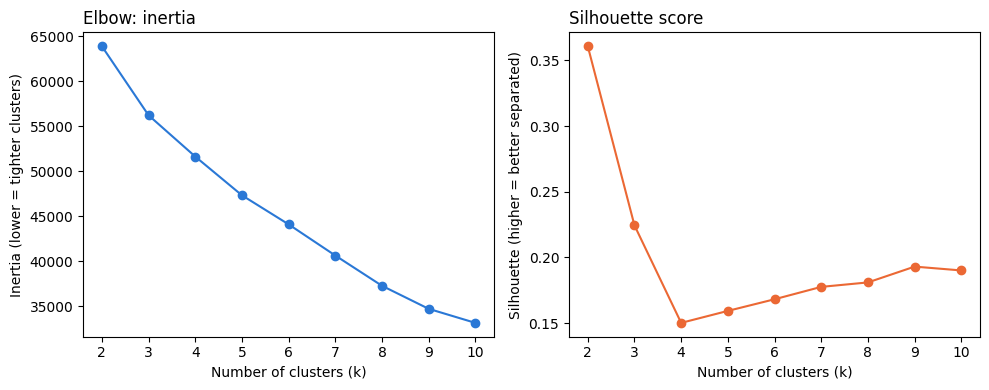

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(list(ks), inertia, marker='o', color='#2a78d6')
axes[0].set_title('Elbow: inertia', loc='left')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (lower = tighter clusters)')
axes[1].plot(list(ks), sil, marker='o', color='#eb6834')
axes[1].set_title('Silhouette score', loc='left')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette (higher = better separated)')
plt.tight_layout()
plt.show()

In [ ]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_pca)
km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_pca)

def cluster_profile(labels):
  tab = pd.DataFrame({'Cluster': labels, 'Target': df['Target'].values})
  sizes = tab.groupby('Cluster').size().rename('Students')
  mix = (pd.crosstab(tab['Cluster'], tab['Target'], normalize='index') * 100).round(1)
  return pd.concat([sizes, mix], axis=1)

print('k = 2')
print(cluster_profile(km2.labels_))
print()
print('k = 5')
print(cluster_profile(km5.labels_))

k = 2
         Students  Dropout  Enrolled  Graduate
Cluster                                       
0            4125     32.7      18.3      49.0
1             299     24.4      13.0      62.5

k = 5
         Students  Dropout  Enrolled  Graduate
Cluster                                       
0            1899     18.7      19.6      61.7
1            1477     27.8      20.7      51.5
2             285     24.2      13.0      62.8
3             712     79.9       9.6      10.5
4              51     33.3      21.6      45.1


In [ ]:
def cluster_means(labels):
  cols = ['Age at enrollment', 'Admission grade', 'Curricular units 1st sem (approved)',
          'Curricular units 1st sem (grade)', 'Debtor', 'Tuition fees up to date',
          'Scholarship holder', 'Gender']
  return X_cl[cols].groupby(labels).mean().round(2)

cluster_means(km5.labels_)

,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Debtor,Tuition fees up to date,Scholarship holder,Gender
0,19.60,126.10,5.36,12.81,0.06,0.95,0.32,0.24
1,25.74,127.77,4.83,12.56,0.14,0.88,0.25,0.40
2,29.07,129.26,11.56,12.61,0.15,0.89,0.11,0.36
3,25.79,126.92,0.02,0.14,0.18,0.69,0.10,0.55
4,20.67,124.52,4.14,10.09,0.12,0.92,0.33,0.27


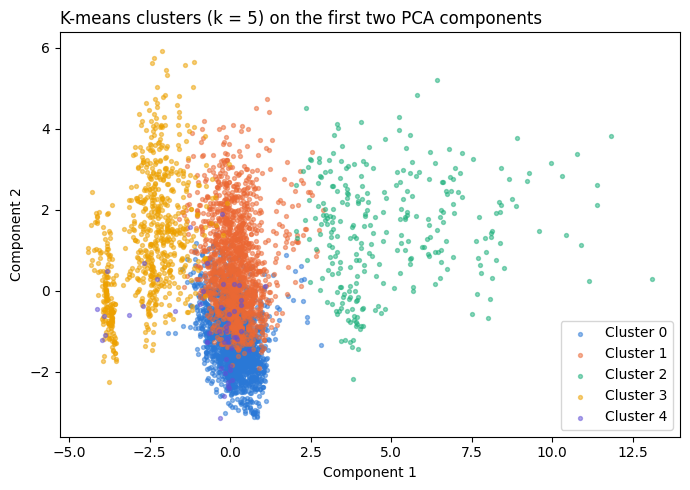

In [ ]:
COLORS5 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6']
Z = X_pca[:, :2]

fig, ax = plt.subplots(figsize=(7, 5))
for c in range(5):
  m = km5.labels_ == c
  ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, color=COLORS5[c], label=f'Cluster {c}')

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_title('K-means clusters (k = 5) on the first two PCA components', loc='left')
ax.legend()
plt.tight_layout()
plt.show()

## Choosing k
- The elbow curve falls smoothly with no sharp bend, so it does not give a clear k
- The silhouette score is highest at k = 2 (0.361) and low for k of 3 or more (0.15 to 0.22), so the clusters overlap and students do not fall into sharply separated groups
- We keep k = 2 as the best-separated split, and k = 5 to get enough readable student profiles. Between k = 4 and k = 8 the silhouette scores barely differ (0.15 to 0.18), so the choice there rests on usefulness

## Student profiles (k = 5)
- Cluster 0 (1,899 students, 18.7% dropout): young students (average age 19.6) who are on track: 5.4 units approved in the first semester, grade 12.8, and 95% have fees up to date. Lowest risk
- Cluster 1 (1,477 students, 27.8% dropout): working-age students (average age 25.7) who are mostly on track. Average risk
- Cluster 2 (285 students, 24.2% dropout): mature students (average age 29.1) with a very heavy first-semester load (11.6 units approved) and few scholarships (11%)
- Cluster 3 (712 students, 79.9% dropout): students who passed almost nothing in the first semester (0.02 units approved, grade 0.1), with the lowest share of fees up to date (69%). This is the highest-risk profile: 16% of students but about 40% of all dropouts
- Cluster 4 (51 students, 33.3% dropout): a very small group in which every student has special educational needs. Too small to interpret
- Only cluster 3 is clearly different in dropout. The silhouette score is low (0.159 at k = 5), so the clusters overlap and the profiles are descriptive groupings, not sharply separated groups
- k = 2 gives a higher silhouette (0.361) but mainly separates a small group of 299 heavy-load students, so its dropout rates barely differ (24.4% versus 32.7%). We therefore use k = 5 for profiling
- These are associations, not causes. A profile is decision support for advisors, never a label to treat a student differently

## Step 4: Hierarchical clustering
Ward hierarchical clustering on the same PCA data, compared with K-means (k = 5).

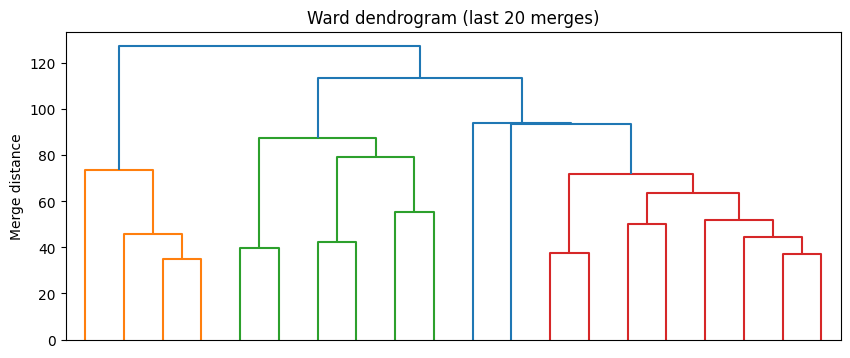

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

Z = linkage(X_pca, method='ward')
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=20, no_labels=True)
plt.title('Ward dendrogram (last 20 merges)')
plt.ylabel('Merge distance')
plt.show()

In [ ]:
for k in range(2, 11):
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_pca)
    print(k, round(silhouette_score(X_pca, lab), 3))

hc5 = AgglomerativeClustering(n_clusters=5, linkage='ward').fit_predict(X_pca)
print('Agreement with K-means (ARI):', round(adjusted_rand_score(km5.labels_, hc5), 3))
print(pd.crosstab(km5.labels_, hc5, rownames=['K-means'], colnames=['Hierarchical']))

2 0.349
3 0.186
4 0.2
5 0.218
6 0.236
7 0.248
8 0.256
9 0.162
10 0.157
Agreement with K-means (ARI): 0.342
Hierarchical    0    1     2   3   4
K-means                             
0             171    9  1676   0  43
1             512   33   891   0  41
2               6  270     2   0   7
3             661   22    14   0  15
4               0    0     0  51   0


## Hierarchical clustering: findings
- Ward clustering on the same PCA data has its highest silhouette at k = 2 (0.349), as K-means does. At k = 5 it is 0.218 (K-means: 0.159)
- Agreement with K-means at k = 5 is low (ARI 0.342), so the two methods do not split the large groups in the same way
- They do agree on the distinctive small groups: all 51 students in K-means cluster 4 (all with special educational needs) form one hierarchical cluster, and 270 of the 285 heavy-load students in cluster 2 stay together
- Conclusion: the distinctive groups are found by both methods, while the large middle groups overlap and are split differently. This fits the weak overall structure

## Step 5: Stability
K-means (k = 5) was rerun with 10 different seeds and compared with the reference run (seed 42).

In [ ]:
rows = []
for s in range(10):
    k5 = KMeans(n_clusters=5, n_init=10, random_state=s).fit(X_pca)
    rows.append((s, adjusted_rand_score(km5.labels_, k5.labels_),
                 silhouette_score(X_pca, k5.labels_)))
stab = pd.DataFrame(rows, columns=['Seed', 'ARI vs seed 42', 'Silhouette']).round(3)
print(stab)
print('Mean ARI:', stab['ARI vs seed 42'].mean().round(3),
      '| Min ARI:', stab['ARI vs seed 42'].min())

   Seed  ARI vs seed 42  Silhouette
0     0           0.326       0.158
1     1           0.999       0.159
2     2           0.999       0.159
3     3           0.999       0.159
4     4           0.941       0.161
5     5           0.811       0.163
6     6           0.475       0.242
7     7           1.000       0.159
8     8           0.497       0.235
9     9           0.326       0.158
Mean ARI: 0.737 | Min ARI: 0.326


## Stability: findings
- Silhouette stays near 0.16 for most seeds, but seeds 6 and 8 find a different solution with a higher silhouette (0.24). The seed-42 run is not the best-scoring one; we keep it so the notebook and the app use the same clusters
- 6 of 10 seeds reproduce the reference clusters almost exactly (ARI 0.81 to 1.00). Mean ARI is 0.737 and the minimum is 0.326, so k = 5 is moderately stable
- Consequence: the exact boundaries of the large groups can shift, so profiles are tendencies, not fixed segments

In [ ]:
labels = km5.labels_
profile = pd.concat([
    pd.Series(labels).value_counts().sort_index().rename('Students'),
    (pd.crosstab(labels, df['Target'].values, normalize='index') * 100).round(1),
    X_cl.groupby(labels).mean().round(2)
], axis=1)
profile.index.name = 'Cluster'
profile.insert(1, 'Share %', (profile['Students'] / len(df) * 100).round(1))
profile

,Students,Share %,Dropout,Enrolled,Graduate,Application order,Age at enrollment,Admission grade,Previous qualification (grade),Curricular units 1st sem (credited),...,Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Debtor,Tuition fees up to date,Scholarship holder,Gender,Displaced,Daytime/evening attendance,Educational special needs,International
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1899,42.9,18.7,19.6,61.7,2.33,19.60,126.10,132.06,0.10,...,12.81,0.08,0.06,0.95,0.32,0.24,0.97,0.99,0.0,0.02
1,1477,33.4,27.8,20.7,51.5,1.12,25.74,127.77,133.44,0.32,...,12.56,0.09,0.14,0.88,0.25,0.40,0.06,0.80,0.0,0.03
2,285,6.4,24.2,13.0,62.8,1.14,29.07,129.26,131.68,8.66,...,12.61,0.44,0.15,0.89,0.11,0.36,0.40,0.73,0.0,0.03
3,712,16.1,79.9,9.6,10.5,1.58,25.79,126.92,132.75,0.00,...,0.14,0.26,0.18,0.69,0.10,0.55,0.49,0.87,0.0,0.02
4,51,1.2,33.3,21.6,45.1,2.04,20.67,124.52,132.44,0.18,...,10.09,0.06,0.12,0.92,0.33,0.27,0.57,0.98,1.0,0.02


In [ ]:
import joblib
from google.colab import files

profile.to_csv('cluster_profiles.csv')
joblib.dump({'scaler': scaler, 'pca': pca, 'kmeans': km5, 'columns': cluster_cols},
            'cluster_model.joblib')
files.download('cluster_profiles.csv')
files.download('cluster_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
rows = []
for s in range(10):
    lab = KMeans(n_clusters=5, n_init=10, random_state=s).fit_predict(X_pca)
    appr = X_cl['Curricular units 1st sem (approved)'].groupby(lab).mean()
    c = appr.idxmin()
    m = lab == c
    rows.append((s, int(m.sum()), round(appr[c], 2),
                 round((df['Target'].values[m] == 'Dropout').mean() * 100, 1)))
pd.DataFrame(rows, columns=['Seed', 'Students', 'Avg approved units', 'Dropout %'])

,Seed,Students,Avg approved units,Dropout %
0,0,636,0.02,77.5
1,1,710,0.02,79.9
2,2,710,0.02,79.9
3,3,710,0.02,79.9
4,4,702,0.02,79.8
5,5,706,0.01,79.6
6,6,646,0.05,78.2
7,7,712,0.02,79.9
8,8,654,0.00,78.0
9,9,638,0.02,77.6


## Stability of the high-risk profile
- In all 10 seeds, the cluster with the fewest approved units has 636 to 712 students (0.00 to 0.05 units approved) and 77.5% to 79.9% dropout
- So the high-risk group (students who pass almost nothing in the first semester) is stable even though the boundaries of the other clusters move

## Overall Clustering Evaluation Conclusion

K-means with five clusters produced useful student profiles. The silhouette score was 0.159, showing that the clusters overlap. Ward hierarchical clustering achieved a silhouette score of 0.218 at five clusters, with an ARI of 0.342 compared with K-means. The ten-seed stability test produced a mean ARI of 0.737. The high-risk group, consisting of students with almost no approved first-semester units, remained identifiable across different seeds.

Therefore, clustering provides useful descriptive student profiles, but the groups are not perfectly separated or completely stable. These profiles show associations, not causes, and should support academic advisors rather than automatically label students.